# Lecture 3 (Part 2): Portfolio Strategies


---

## 3.1 What a portfolio actually is

A **portfolio** is a collection of assets
 - represented by a set of weights $\mathbf{w}  = (\mathrm{w_1},\dots,\mathrm{w_N})$
 - Weights $\mathrm{w_i}$ indicate how much you invest in asset $i$ relative to other assets

Long position: $\mathrm{w_i}>0$
 - **Long-only portfolio**: $\mathrm{w_i} > 0$ for all assets $i$ in the portfolio

Short position: $\mathrm{w_i}<0$
  - Borrow asset $i$ and sell it (then buy back later at a hopefully lower price)

One of the assets can be a risk-free asset (often called "cash")
 - $\mathrm{w_f}>0$: invest at the risk-free rate
 - $\mathrm{w_f}<0$: borrow at the risk-free rate - **leverage**

**Ordinary portfolios: weights sum to 1.** With €1,000:
- Long-only: €600 in EDP, €400 in CTT → $\mathrm{w}_E = 0.6$, $\mathrm{w}_C = 0.4$
- Leveraged: €800 in EDP, €500 in CTT, −€300 risk-free → $\mathrm{w}_E = 0.8$, $\mathrm{w}_C = 0.5$, $\mathrm{w}_f = -0.3$

**Self-financing portfolios: weights sum to 0** — you start with *none* of your own money; the short leg finances the long leg (e.g., sell €1,300 of Galp short, buy €800 EDP + €500 CTT).

How realistic are self-financing portfolios?
 - Would you lend me €10,000 cash to invest in a portfolio of risky assets with $0$
 of my own money?
 - Would you lend me €10,000 in shares of Galp to invest in a portfolio of risky assets with $0$  of my own money?
 - Nevertheless, useful theoretical construct to study the relative performance of different assets or portfolios
 - It makes money if and only if the long leg outperforms the short leg
 - Connection to expected *excess* returns: $E[R^p] - R_f$ $→$  self-financing portfolio that borrows at $R_f$ and invests in portfolio $p$  earning $E[R^p]$ in expectation.


#### Portfolios vs. Portfolio Strategies
Portfolio is a static concept
 - Weights are fixed at a point in time
 - Define how much we currently have invested in each firm

Portfolio strategy is a dynamic concept
 - Approach to changing portfolio weights over time
 - Rebalancing: buying and selling assets to achieve a target portfolio

A rules-based portfolio strategy follows a set of pre-specified rules to determine how to rebalance
 - Instead of the portfolio manager using their discretion and judgment to decide how to trade
 - For example, fixed weights strategy: **buy and hold** the same portfolio weights forever
 - For example, buy all stocks in the S&P 500 in proportion to their market capitalization

**Fixed weights strategy**: buy and hold the same portfolio weights forever:
 - For example, $\mathrm{w_E} = 0.6, \mathrm{w_C} = 0.4$
 - Holding weights fixed takes work! You must rebalance to maintain weights
 - Today, we use €1,000 to implement the strategy by buying
   - 150 shares of EDP at €4 a share = €600
    - 80 shares of CTT at €5 a share = €400
 - In a month, EDP is at €5 a share, CTT is at €5.5 a share
    - Value of the EDP position: 150 x €5 = €750
    - Value of the CTT position: 80 x €5.5 = €440
    - New weights: $\mathrm{w}_E = 750/(750+440) = 0.63$, $\mathrm{w}_C = 440/(750+440) = 0.37$
    - Need to sell 150-(1190 x 0.6/5) = 7.2 shares of EDP and buy 1190 x 0.4/5.5-80 = 6.5  shares of CTT to get back to 60/40 split

**Passive strategy**: "set it and forget it."

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
!pip -q install quantstats
import quantstats as qs

---
## 3.2 The strategy to beat: 1/n

Our strategy of interest is the **equally-weighted (1/n) portfolio** of large US financial-sector stocks: equal money in each, no optimization, no forecasting. It sounds too naive to matter, but DeMiguel, Garlappi, and Uppal (2009) show that 1/n is hard to beat. Today it is our vehicle for learning how to **evaluate** any strategy: alpha, beta, Sharpe ratio, information ratio, drawdowns.

We take a list of large financial-services names and retrieve their data from Yahoo Finance.

In [ ]:
tickers_fin = ['JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'BLK', 'SCHW',
               'AXP', 'V', 'MA', 'BX', 'KKR', 'CB', 'PGR']

df = yf.download(tickers_fin,
                 start='2010-12-01', end='2024-12-01',
                 interval='1mo', auto_adjust=True, progress=False)
df = df['Close']

# benchmark: the S&P 500 index total return (including distributions)
df_benchmark = yf.download('^SP500TR',
                           start='2010-12-01', end='2024-12-01',
                           interval='1mo', auto_adjust=True, progress=False)
df_benchmark = df_benchmark['Close']
# check shape and dates
print(df.shape, df.index.min(), df.index.max())
# look at df
df.head()

In [ ]:
# check: the plot
df.loc[:, ['GS', 'JPM', 'C', 'WFC', 'BAC', 'V', 'MA']].plot(
    title="Financial Services stocks, 2011-2024");

Compute log returns and deal with missing values — *knowingly*. We allow one missing value per column, from the return computation itself, and drop columns with longer gaps:

In [ ]:
returns = np.log(df) - np.log(df.shift(1))     # shift(1): the previous month's price

ind_na = np.sum(returns.isna(), axis=0)        # missing values per column
returns = returns.iloc[:, list(ind_na <= 1)]   # keep columns with at most 1 NaN
returns = returns.dropna()

n_assets = returns.shape[1]
portfolio_weights = np.ones(n_assets) * (1/n_assets)

sp500 = np.log(df_benchmark) - np.log(df_benchmark.shift(1))
sp500 = sp500.dropna()

# remove timezone information so the two series align
sp500 = sp500.tz_localize(None)
returns = returns.tz_localize(None)

# 1/n portfolio returns: weights times asset returns
portfolio_returns = pd.DataFrame(np.dot(portfolio_weights, returns.T),
                                 index=returns.index, columns=['ptf'])

---
## 3.3 Alpha and beta: how much is skill, how much is the market?

The most basic measure of trading performance is, of course, the return, $R_t$, in a given period, $t$. The return is often separated
into its alpha and beta. **Beta** is the strategy's **market exposure**, while **alpha** is the **excess return after accounting for performance due to market movements**. Alpha and beta are computed by
running a regression of the strategy's return in excess of the risk-free rate $R^f$, $R_t^{ex} = R_t - R^f$, on the excess return of the market, $R_t^{M,ex}$:
$$R_t^{ex} = \alpha + \beta R_t^{M,ex} + ɛ_t$$

Here, $\beta$ (beta) measures **the strategy's tendency to follow the market**. For example, suppose that $\beta = 0.5$. This means that if the market goes up by 10%, this strategy goes up by 0.5 x 10% = 5%, everything else being equal. For instance, if you invest half of your money in the stock market and the other half in cash, then your overall portfolio has a $\beta$ of 0.5. In that case, your excess return will literally be 5% when the market goes up by 10%.

More generally, your performance also depends on your **idiosyncratic risk**, measured by $ɛ_t$. For instance, if you only invest in biotech stocks rather than the overall market,
then $ɛ_t$ is the relative outperformance of your biotech stocks vis-à-vis the market. The idiosyncratic risk can be positive or negative, is zero on average, and is independent of market moves.

In the hedge fund industry, **alpha** measures
the strategy's **value added above and beyond the market exposure** due to the
hedge fund's trading skill (or luck, given that alpha is estimated based on realized
returns). If a hedge fund has a beta of zero (i.e., a market-neutral hedge fund) and an
alpha of 6% per year, this means that the hedge fund is expected to make the
risk- free return plus 6% per year. For instance, if the risk-free rate is 2% per
year, the hedge fund is expected to make 8%, but the actual realization could be
far above or below that, depending on the realized idiosyncratic shock.

**Estimation**: we can estimate beta without running a regression using the formula:

$$\beta = \frac{cov(R_t^{ex}, R_t^{M,ex})}{var(R_t^{M,ex})} $$

Then alpha is $\alpha = E[R_t^{ex}] - \beta E[R_t^{M,ex}]$.

Finally, we can estimate full-sample alpha and beta utilizing the entire sample of the available data. However, it is more useful to see how alpha and beta change over time. For this reason, we can use the rolling-window estimates with alpha and beta estimated using 60 monthly observations. We start by using the first 60 observations, then we "roll" or shift the window by one month to the future. We continue shifting the estimation window until we reach the end of the sample.

### Discussion

Our portfolio is 1/n in *banks, brokers, and payment firms*, benchmarked on the S&P 500. Do you expect $\beta$ **(a)** clearly below 1 **(b)** about 1 **(c)** above 1? And in which sample years would you expect beta to spike?

In [ ]:
# rolling 60-month regression, computed by hand (rf assumed 0)
window = 60
s = sp500['^SP500TR']
p = portfolio_returns['ptf']

rolling_beta = p.rolling(window).cov(s) / s.rolling(window).var()
rolling_alpha = p.rolling(window).mean() - rolling_beta * s.rolling(window).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(rolling_beta, color='blue');  ax1.set_title('Rolling Beta');  ax1.set_ylabel('Beta')
ax2.plot(1200 * rolling_alpha, color='green')   # monthly, decimal -> annual, percent: x 12 x 100
ax2.set_title('Rolling Alpha'); ax2.set_xlabel('Date'); ax2.set_ylabel('Alpha (% p.a.)')
plt.tight_layout(); plt.show()

**Discussion:** in the alpha plot's code there is a factor `1200`. Why?

The same rolling greeks in one call, using `quantstats`:

In [ ]:
alpha_beta_rolling = qs.stats.rolling_greeks(p, benchmark=s,
                                             periods=60, prepare_returns=False)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(alpha_beta_rolling['beta'], color='blue');   ax1.set_title('Rolling Beta')
ax2.plot(1200 * alpha_beta_rolling['alpha'], color='green'); ax2.set_title('Rolling Alpha')
plt.tight_layout(); plt.show()

---
## 3.4 Risk-reward ratios

The alpha of the portfolio strategy is far from a perfect metric of its performance.
First, while alpha tells you the size of the returns that a strategy
delivers above the market exposure, it does not say at what risk. Second, alpha depends on how a strategy is scaled; for instance, a twice-leveraged strategy has twice the alpha of an unleveraged version of the same strategy. However, the quality of the strategy is what it is, so the performance measure should arguably be the same in both cases.

Risk-reward ratios resolve these issues. At a basic level, potential investors in a portfolio strategy want to know how the future expected excess return $E(R-R^f)$
compares to the risk that the strategy is taking. The **Sharpe ratio (SR)** is a
measure of just that and is also called the risk-adjusted return. It measures the investment "reward" per unit of risk:
$$SR = \frac{E(R-R^f)}{\sigma(R-R^f)} = \frac{Avg. Excess\;Return}{Volatility}$$

Investors prefer higher Sharpe ratio, as they prefer higher returns and lower risk (but their preferences might be more complex than what is captured by the Sharpe ratio when
the portfolios have skewed returns and crash risk).

In [ ]:
SR_qs = qs.stats.sharpe(p, periods=12, annualize=True)
print(f"Sharpe ratio (quantstats): {SR_qs:.2f}")

r_f = 0
SR_monthly = (p.mean() - r_f) / p.std()
SR_annualized = (12 * (p.mean() - r_f)) / (np.sqrt(12) * p.std())
print(f"Monthly Sharpe ratio:     {SR_monthly:.2f}")
print(f"Annualized Sharpe ratio:  {SR_annualized:.2f}")

**Check:** the annualized number is the monthly one times... what? ($12/\sqrt{12} = \sqrt{12} \approx 3.46$.) Remember: **means scale with time, volatilities with its square root.**

The SR gives the portfolio strategy credit for all excess returns, but we learned above that there is a difference between alpha returns and simple market exposure.
**The information ratio (IR)** focuses on the risk-adjusted abnormal return or, said differently, the risk-adjusted alpha:

$$IR = \frac{\alpha}{\sigma(\varepsilon)}$$

The alpha and idiosyncratic risk $\varepsilon$ come from a regression of the hedge fund's excess return on some benchmark with excess return $R^b$,
$$R_t^{ex} = \alpha + \beta R_t^{b,ex} + ɛ_t$$
If the hedge fund has a mandate to beat a specific benchmark, then the IR is
often computed without running a regression. In this case, the IR is computed
simply as the expected return in excess of the benchmark, relative to the volatility
of this outperformance:
$$IR = \frac{E(R-R^b)}{\sigma(R-R^b)} $$

Hence, the $IR$ measures the extent to which the strategy beats the benchmark per unit of **tracking error risk**. Tracking error is the difference between the strategy's
and the benchmark's returns, and tracking error risk is the standard deviation of
this difference.

In [ ]:
IR_qs = qs.stats.information_ratio(p, benchmark=s, prepare_returns=False)
print(f"Information ratio (quantstats): {IR_qs:.2f}")

tracking_error = p - s      # more precisely we are interested in tracking_error.std()
IR_monthly = tracking_error.mean() / tracking_error.std()
IR_annualized = (12 * tracking_error.mean()) / (np.sqrt(12) * tracking_error.std())
print(f"Monthly IR:    {IR_monthly:.2f}")
print(f"Annualized IR: {IR_annualized:.2f}")

---
## 3.5 Drawdowns: the risk your clients actually feel

A portfolio strategy's **high water mark (HWM)** is the highest price $P_t$ (or highest
cumulative return) it has achieved in the past:
$$HWM_t  = \max_{s \leq t} P_s$$

Often hedge funds only charge performance fees when their returns are above their HWM. Hence, if they have experienced losses, they must first make these back and only charge performance fees on the profits above their HWM.

An important risk measure for a hedge fund strategy is its drawdown (DD). The **drawdown** is the cumulative loss since losses started. The **percentage drawdown** since the peak (i.e., the HWM) is given by

$$DD_t = (HWM_t - P_t)/HWM_t $$
where $P_t$ is the cumulative return at time $t$ (or share price). In other words, the
drawdown is the amount that has been lost since the peak (i.e., the HWM). If the portfolio strategy is currently at its peak, then the drawdown is zero, and otherwise it is
a positive number. The drawdown can also be measured relative to other points
in time, for example, the beginning of the year. Experiencing large drawdowns
is costly and risky. In addition to the direct losses, large drawdowns often lead
to **redemptions from investors** and concerns from counterparties, for example,
prime brokers increasing **margin requirements** or completely pulling the financing of the hedge fund's positions. When evaluating a strategy, people sometimes
consider its **maximum drawdown (MDD)** over some past time period:
$$MDD_T = \max_{t\leq T} DD_t$$

Text and figure adapted from Pedersen (2015), ch. 2.
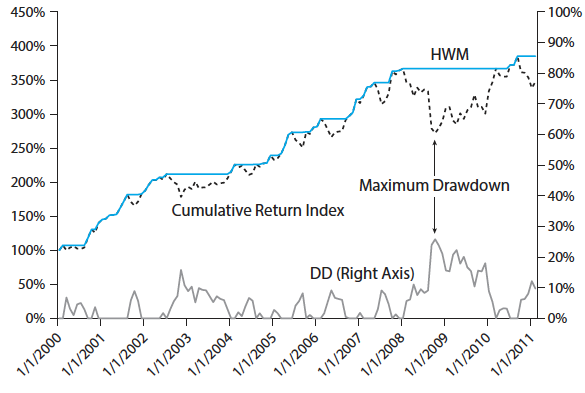

In [ ]:
# the full quantstats tear sheet: dozens of metrics incl. max drawdown
qs.reports.metrics(p, benchmark=s, periods_per_year=12, prepare_returns=False)

In [ ]:
qs.plots.drawdowns_periods(p, fontname="Sans Serif", title="1/n Financial stocks")

---
## 3.6 Practice: The AI wrote it — should you trust it?

A student asked an AI: *"Compute the annualized Sharpe ratio of an equal-weighted portfolio of my stocks from the DataFrame `df` of monthly prices."* The answer runs, and prints a Sharpe ratio a hedge fund would kill for. **Find all the problems before opening the solution.** Rank them by how much they inflate the number.

In [ ]:
# --- AI-generated code: DO NOT TRUST -- find the bugs -----------------
ptf_series = df.mean(axis=1)                    # equal-weighted portfolio
sharpe = ptf_series.mean() / ptf_series.std() * np.sqrt(12)
print(f"Annualized Sharpe ratio: {sharpe:.2f}")

<details>
<summary> <b>Solution</b></summary>

**Bug 1 — it computed the Sharpe ratio of *prices*, not returns.** `df` holds monthly *prices*; `df.mean(axis=1)` averages price levels, and `mean()/std()` of a steadily rising price series is a huge number that means nothing. A Sharpe ratio is defined on **returns**. (The give-away that something is off: no real strategy has a Sharpe ratio of 8 — plausibility is a check too.)

**Bug 2 — "equal-weighted" done on prices is not equal-weighted anyway.** Averaging *prices* across stocks weights the portfolio towards high-*price* stocks (a €900 stock counts 9$\times$ a €100 stock) — that is a price-weighted index (the Dow's famous flaw), not 1/n. Equal weighting happens on **returns**: `rets.mean(axis=1)`.

**Bug 3 — no risk-free rate**: raw mean, not excess return.

Correct version:

```python
rets = np.log(df).diff(1).dropna()
ptf = rets.mean(axis=1)                       # 1/n on returns
rf = 0.0
sharpe = (12*ptf.mean() - rf) / (np.sqrt(12)*ptf.std())   # subtract rf when > 0
print(f"{sharpe:.2f}")
```

The deeper lesson: the AI answered the question as literally asked — "of the DataFrame `df`" — and `df` held prices. **The ambiguity you leave in the prompt comes back as silent assumptions in the code.**
</details>

---
## 3.7 Homework: build and judge your own 1/n

Pick 8–15 stocks from a *different* sector (or a European universe — `.LS`, `.DE` suffixes), 2011–2024 monthly. Build the 1/n portfolio and produce: rolling beta, annualized Sharpe, information ratio vs. a suitable benchmark (is the S&P 500 still the right one for a European universe?), and the drawdown plot.

